# Chapter 12. Deep Computer Vision using Convolution Neural Networks

This chapter focuses on Convolution Neural Networks (CNNs) which have been around since the 80s and used to research and develop perception for computers. Just as we process our world vidually with specialized intution of features, CNNs attempt to as well. They are also applied to other domains such as audio and natural language processing.

### The visual cortex

Studies of the architecture of real neurons in the visual cortex found a design that involved local neurons keying into specific patterns in small regions of teh visual field called 'receptive fields'; this was fed upward to neurons with larger receptive fields. Sciencists believed that the inputs to these higher-level neurons was the ouptut of the lower-level neurons and allows the visual cortex to identify complex patterns that are derived from the small ones in lower levels.

A groundbreaking 1998 paper by Yann LeCun introduced the _LeNet-5_ architecture, which was used by banks to recognize handwritten digits on checks.


The key elements this model architecture introduced for CNNs was the building blocks of _convolutional layers_ and _pooling layers_.

### Convolutional Layers
The most important building block in which neurons are connected to specific receptive fields, not every single pixel and following a hierarchical structure that allows them to concentrate small low-level features in one layer, and assemble them into larger higher-level features in the next.

- _zero padding_ : Adding zeroes around inputs in order for a layer to have the same height and width as the previous layer
- _stride_ : The horizontal or vertical step size from one receptive field to the next - helpful for reducing computational complexity when feeding a large input layer to a smaller layer

#### Filters
A neuron's weights can be represented as a small image the size of the receptive field. These are called _filters_ or _convolution kernels_.

Using this technique neurons can focus on particular aspects of an image by ignoring or filtering out everything else, this contrasts CNNs from other deep learning methods where the goal is to divide the system into a sequence of specialized modules. A layer full of neurons using the same filter outputs a _feature map_, which highlights the areas in an image that activate the filter the most.

A convolutional layer simultaneously applies multiple trainable filters to its inputs, making it capable of detecting multiple features anywhere in its inputs. What this meens is that the feature maps chare parameters which redcuces the number of parameter in the model, so once the CNN has leanred to recognize a pattern in one location, it can recognize it in any other location.

#### Implementing Convolutional Layers with PyTorch

Loading sample images represented as a Python list of NumPy unsigned byte arrays, so stack these images into a single NumPy array, then convert it to a 32-bit floating point tensor, and rescale the pixel values from 0-255 to 0-1:

In [40]:
import numpy as np
import torch
from sklearn.datasets import load_sample_images

sample_images = np.stack(load_sample_images()["images"])  # why do we stack?
print(f"Loaded {len(sample_images)} images, of shape {sample_images[0].shape}")
sample_images = torch.tensor(sample_images, dtype=torch.float32) / 255

Loaded 2 images, of shape (427, 640, 3)


In [41]:
print(sample_images.shape)

torch.Size([2, 427, 640, 3])


The numbers represent the number of images (2), height (427), width (640) in pixesl, and the number of color channels (3) representing red, green, and blue. PyTorch expects the channel dimension before height and width, so we need to permute the dimensions using the `permute()` method:

In [42]:
sample_images_permuted = sample_images.permute(0, 3, 1, 2)  # pyright: ignore[reportAttributeAccessIssue]
print(sample_images_permuted.shape)

torch.Size([2, 3, 427, 640])


We'll also add a center crop

In [43]:
import torchvision
import torchvision.transforms.v2 as T

cropped_images = T.CenterCrop((70, 120))(sample_images_permuted)
print(cropped_images.shape)

torch.Size([2, 3, 70, 120])


PyTorch provides teh `nn.Conv2d` layer for creating convolutional layers, here we'll create one with 32 filters each of size 7x7 `kernel_size=7` and apply it to our two images.

In [44]:
import torch.nn as nn  # noqa: PLR0402

torch.manual_seed(42)
conv_layer = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=7)
feature_maps = conv_layer(cropped_images)
print(feature_maps.shape)

torch.Size([2, 32, 64, 114])


The model got 32 output channels as we specified, from the original 3, but it also lost some size losing 6 pixels in each dimension (length and width). This is due to the default padding being 0 or _valid_ with the function we used. Setting `padding="same"` will keep things .. the same.

In [45]:
conv_layer = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=7, padding="same")

In [46]:
feature_maps = conv_layer(cropped_images)
print(feature_maps.shape)

torch.Size([2, 32, 70, 120])


An `nn.Conv2d` layer holds all the layer's parameters, including the kernels and biases, _weight_ and _bias_ attributes.

In [47]:
print(f"weight: {conv_layer.weight.shape}")
print(f"bias: {conv_layer.bias.shape}")  # type: ignore

weight: torch.Size([32, 3, 7, 7])
bias: torch.Size([32])


### Pooling Layers
These layers enable a reduction in parameters neeeded to train by performing subsampling methods such as taking all the maximums in a layer size.


#### Implementing Pooling Layers with PyTorch
We can use `nn.MaxPool2d` layer using a 2x2 keernel, strides default ot the kernel size and `padding=0` (i.e., "valid" padding (no padding)):

In [48]:
max_pool = nn.MaxPool2d(kernel_size=2)

In [49]:
output = max_pool(cropped_images)
print(output.shape)

torch.Size([2, 3, 35, 60])


### CNN Architectures
The basic design pattern is to start with a larger first convolutional layer and then stack smaller layers separated by +ReLU activation layers, followed by a pooling layer, and so on. Finally a fully connected layer composes the final output predictions.

A basic CNN to tackel the Fashion MNIST dataset:

QUESTION: Where do the in and out channels calculations happen how do I know what to put there? I obviously understand they need to align in order in -> out but are we always doubling (we aren't) and why?

QUESTION: Why/how does a dropout layer prevent overfitting

In [50]:
from functools import partial

DefaultConv2d = partial(nn.Conv2d, kernel_size=3, padding="same")
model = nn.Sequential(
    # First convolutional layer, larger kernel
    DefaultConv2d(in_channels=1, out_channels=64, kernel_size=7),
    # Activation Layer
    nn.ReLU(),
    # Pooling Layer
    nn.MaxPool2d(kernel_size=2),
    # Second conv layer, deafult kernel size
    DefaultConv2d(in_channels=64, out_channels=128),
    nn.ReLU(),
    DefaultConv2d(in_channels=128, out_channels=128),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),
    DefaultConv2d(in_channels=128, out_channels=256),
    nn.ReLU(),
    DefaultConv2d(in_channels=256, out_channels=256),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),
    # Fully Connected Network
    nn.Flatten(),
    # 1st Hidden dense layer
    nn.Linear(in_features=2304, out_features=128),
    nn.ReLU(),
    nn.Dropout(0.5),
    # 2nd Hidden dense layer
    nn.Linear(in_features=128, out_features=64),
    nn.ReLU(),
    # 50% Dropout layer reduces overfitting
    nn.Dropout(0.5),
    # Output layer has 10 features, one for each class
    nn.Linear(in_features=64, out_features=10),
).to(device="mps")

Chapter 10 under Using TorchVision to Load the Dataset (~pg.586) has the example for using the torchvision library for gathering our datasets.

In [51]:
toTensor = T.Compose([T.ToImage(), T.ToDtype(torch.float32, scale=True)])

train_and_validate_data = torchvision.datasets.FashionMNIST(
    root="datasets", train=True, download=True, transform=toTensor
)

test_data = torchvision.datasets.FashionMNIST(
    root="datasets", train=False, download=True, transform=toTensor
)

train_size = int(0.8 * len(train_and_validate_data))
validate_size = len(train_and_validate_data) - train_size

train_data, validate_data = torch.utils.data.random_split(
    train_and_validate_data, [train_size, validate_size]
)

This code transformed the FashionMNIST dataset with a composed Tensor transforming first to an image type that TorchVision can understand, and then the proper data type. It then uses that to download the data and split the train and validate sets.

In [52]:
from torch.utils.data import DataLoader

batch_size = 32  # should this be matched up with th ekernel at all?

train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
valid_loader = DataLoader(validate_data, batch_size=batch_size)
test_loader = DataLoader(test_data, batch_size=batch_size)

In [53]:
X_sample, y_sample = train_data[0]  # type: ignore
X_sample.dtype

torch.float32

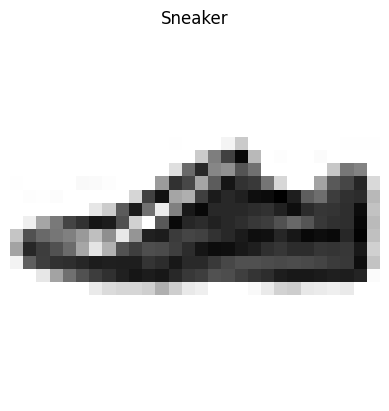

In [54]:
import matplotlib.pyplot as plt

X_sample, y_sample = train_data[0]  # pyright: ignore[reportGeneralTypeIssues]

plt.imshow(X_sample.squeeze(0), cmap="binary")  # [1, 28, 28] -> [28, 28]
plt.title(train_and_validate_data.classes[y_sample])
plt.axis("off")
plt.show()


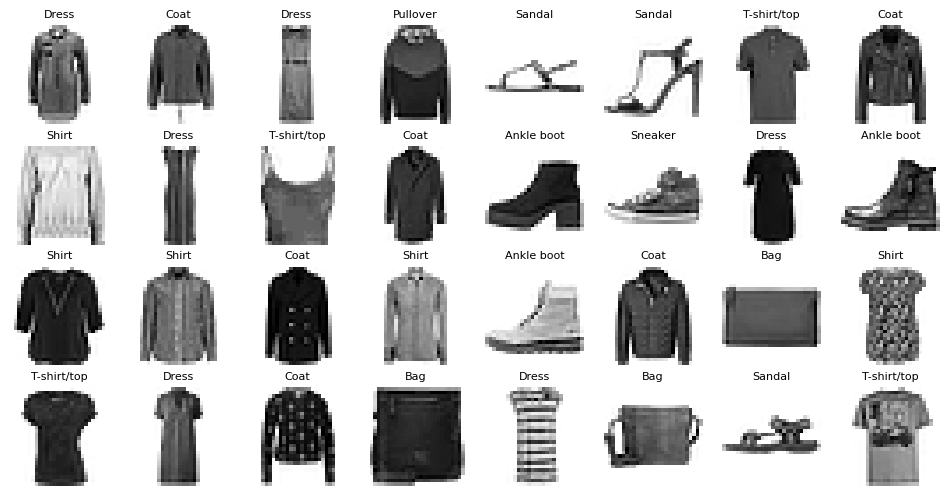

In [55]:
X_batch, y_batch = next(iter(train_loader))  # X_batch: [32, 1, 28, 28]

fig, axes = plt.subplots(4, 8, figsize=(12, 6))
for ax, img, label in zip(axes.flat, X_batch, y_batch):
    ax.imshow(img.squeeze(0), cmap="binary")
    ax.set_title(train_and_validate_data.classes[label], fontsize=8)
    ax.axis("off")
plt.show()


In [56]:
if torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

In [57]:
import torchmetrics

accuracy = torchmetrics.Accuracy(task="multiclass", num_classes=10).to(device)


def evaluate(model, loader, metric):
    model.eval()  # This sets `model.training` to False, read by some layers
    metric.reset()
    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            metric.update(y_pred, y_batch)
    return metric.compute()

In [58]:
def train(model, optimizer, criterion, train_loader, n_epochs):
    for epoch in range(n_epochs):
        model.train()
        total_loss = 0
        for x_batch, y_batch in train_loader:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)
            y_pred = model(x_batch)
            loss = criterion(y_pred, y_batch)
            total_loss += loss.item()
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
        val_accuracy = evaluate(model, valid_loader, accuracy)
        mean_loss = total_loss / len(train_loader)
        print(
            f"Epoch {epoch + 1}/{n_epochs}, Loss: {mean_loss:.4f}, Accuracy: {val_accuracy.item():.4f}"
        )

We can re-use our batch gradient descent based trainer function from Chapter 10. The only caveat is that `model.train()` has moved inside the epoch loop, running at the start of every epoch because our CNN has a `Dropout` layer that reads the `model.training` flag. Because of how dropout randomly eroes hafl the inputs and doubles the rest (to maintain the average), it's typically only turned on for training. Because we are calling an evaluate function at the end of each epoch this uses `model.eval()` which sets the flag to False.

In [59]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9)

In [61]:
train(model, optimizer, criterion, train_loader, n_epochs=10)

Epoch 1/10, Loss: 0.3472, Accuracy: 0.8758
Epoch 2/10, Loss: 0.3255, Accuracy: 0.8980
Epoch 3/10, Loss: 0.3056, Accuracy: 0.9013
Epoch 4/10, Loss: 0.2893, Accuracy: 0.9030
Epoch 5/10, Loss: 0.2744, Accuracy: 0.8998
Epoch 6/10, Loss: 0.2576, Accuracy: 0.9013
Epoch 7/10, Loss: 0.2464, Accuracy: 0.9047
Epoch 8/10, Loss: 0.2374, Accuracy: 0.9091
Epoch 9/10, Loss: 0.2271, Accuracy: 0.9133
Epoch 10/10, Loss: 0.2138, Accuracy: 0.9165
